# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm
**Dua e Zainab | FA34-BAI-027**

**Research question:** Can Genetic Algorithm (GA)-based feature selection improve the classification performance of HOG features while reducing feature dimensionality on medical images?

**Pipeline:** Image → grayscale 128×128 → HOG (8100 features) → **GA feature selection (validation macro-F1 − penalty)** → RBF-SVM → metrics

**Link to Lab 05.** This notebook reuses the Lab 05 pipeline (grayscale → HOG 8×8 / 9 orientations → SVM, same metric helpers) and fixes two weaknesses: Lab 05 picked its HOG settings by looking at *test* scores, whereas here every choice (SVM hyper-parameters, GA settings) is made on the **validation set only**, and the test set is touched once at the very end. Set `DATASET = "neu"` in the config cell to run the same GA-HOG pipeline on the Lab 05 steel-defect data.

**Dataset:** BloodMNIST at 128×128 (8 blood-cell classes; official train/val/test split of 11,959 / 1,712 / 3,421 images). Run all cells top to bottom. A GPU runtime (Runtime → Change runtime type → T4) makes the GA about 10-20× faster but is optional.

## Setup and configuration

In [1]:
!pip -q install scikit-image opencv-python-headless joblib kagglehub

In [2]:
import os, re, glob, time, json, hashlib, warnings, shutil
import numpy as np, pandas as pd, cv2, requests
import matplotlib.pyplot as plt, seaborn as sns
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             cohen_kappa_score, matthews_corrcoef, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")
try:
    import torch
    DEV = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    torch, DEV = None, "numpy"
print("Kernel backend:", DEV)

# ------------------------------ configuration ------------------------------
DATASET  = "bloodmnist"      # "bloodmnist" | "pneumoniamnist" | "neu" (Lab 05 steel-defect data)
SEED     = 42                # fixed random seed (all splits, GA runs, SVMs)
IMG_SIZE = 128
QUICK    = False             # True = smaller GA (about 3x faster) for a trial run
OUT      = "results"; os.makedirs(OUT, exist_ok=True)

HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")  # Table 1
N_SUB        = 2500 if DEV == "cuda" else 1200   # stratified training subset used for GA fitness / tuning
MIN_FEATURES = 100                               # a chromosome must keep at least this many HOG features

# GA settings compared in the experiment (population size and mutation probability are varied)
GA_CONFIGS = {
    "GA-1": dict(pop=16, gens=20, pc=0.9, pm=0.002, alpha=0.02, tour=3, elite=2),
    "GA-2": dict(pop=24, gens=20, pc=0.9, pm=0.005, alpha=0.02, tour=3, elite=2),
    "GA-3": dict(pop=24, gens=20, pc=0.9, pm=0.010, alpha=0.02, tour=3, elite=2),
}
if QUICK:
    for c in GA_CONFIGS.values(): c["pop"] = max(8, c["pop"] // 2); c["gens"] = 10

np.random.seed(SEED)

Kernel backend: cuda


## Task 1: Select a medical image dataset

MD5 check: OK
Dataset: bloodmnist | classes: 8


,train,val,test,Total
basophil,852,122,244,1218
eosinophil,2181,312,624,3117
erythroblast,1085,155,311,1551
immature_granulocyte,2026,290,579,2895
lymphocyte,849,122,243,1214
monocyte,993,143,284,1420
neutrophil,2330,333,666,3329
platelet,1643,235,470,2348


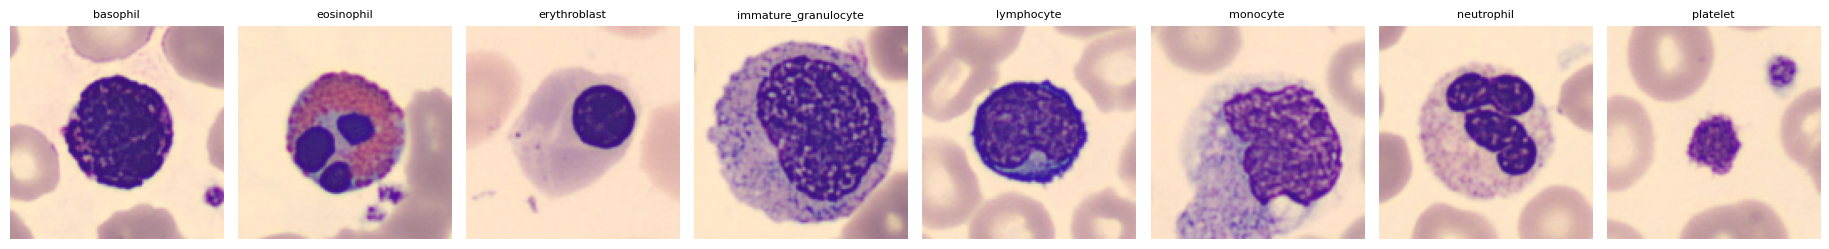

In [3]:
MED = {
    "bloodmnist": dict(url="https://zenodo.org/records/10519652/files/bloodmnist_128.npz?download=1",
                       md5="adace1e0ed228fccda1f39692059dd4c",
                       classes=["basophil", "eosinophil", "erythroblast", "immature_granulocyte",
                                "lymphocyte", "monocyte", "neutrophil", "platelet"]),
    "pneumoniamnist": dict(url="https://zenodo.org/records/10519652/files/pneumoniamnist_128.npz?download=1",
                           md5="05b46931834c231683c68f40c47b2971", classes=["normal", "pneumonia"]),
}

def download(url, path, md5=None):
    if not os.path.exists(path):
        print("Downloading", url.split("?")[0].split("/")[-1], "...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(path, "wb") as f:
                for chunk in r.iter_content(1 << 20): f.write(chunk)
    if md5:
        h = hashlib.md5()
        with open(path, "rb") as f:
            for b in iter(lambda: f.read(1 << 24), b""): h.update(b)
        print("MD5 check:", "OK" if h.hexdigest() == md5 else "MISMATCH (delete the file in data/ and re-run)")

def load_dataset(name):
    if name in MED:
        os.makedirs("data", exist_ok=True); p = f"data/{name}_128.npz"
        download(MED[name]["url"], p, MED[name]["md5"])
        d = np.load(p)
        raw = {s: (d[f"{s}_images"], d[f"{s}_labels"].ravel().astype(int)) for s in ("train", "val", "test")}
        return raw, MED[name]["classes"]
    import kagglehub                                   # Lab 05 steel-defect data, fixed 70/15/15 stratified split
    root = kagglehub.dataset_download("sovitrath/neu-steel-surface-defect-detect-trainvalid-split")
    files = sorted(p for p in glob.glob(root + "/**/*", recursive=True) if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")))
    labs = [re.sub(r"[_-]?\d+$", "", os.path.splitext(os.path.basename(p))[0]) for p in files]
    classes = sorted(set(labs)); y = np.array([classes.index(l) for l in labs])
    imgs = np.array([cv2.resize(cv2.imread(p, 0), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA) for p in files])
    i_tr, i_tmp = train_test_split(np.arange(len(y)), test_size=0.30, stratify=y, random_state=SEED)
    i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=y[i_tmp], random_state=SEED)
    return {"train": (imgs[i_tr], y[i_tr]), "val": (imgs[i_va], y[i_va]), "test": (imgs[i_te], y[i_te])}, classes

raw, classes = load_dataset(DATASET)
K = len(classes)
print("Dataset:", DATASET, "| classes:", K)
display(pd.DataFrame({s: np.bincount(raw[s][1], minlength=K) for s in raw}, index=classes).assign(
        Total=lambda d: d.sum(axis=1)))

fig, ax = plt.subplots(1, K, figsize=(2.3 * K, 2.6))
for a, k in zip(np.atleast_1d(ax), range(K)):
    im = raw["train"][0][np.where(raw["train"][1] == k)[0][0]]
    a.imshow(im, cmap="gray" if im.ndim == 2 else None); a.set_title(classes[k], fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/dataset_samples.png", dpi=120); plt.show()

## Task 2: Preprocessing and fixed train / validation / test split

In [4]:
def preprocess(a):
    if a.ndim == 4 and a.shape[-1] == 3:
        a = np.stack([cv2.cvtColor(np.ascontiguousarray(x), cv2.COLOR_RGB2GRAY) for x in a])   # grayscale
    elif a.ndim == 4:
        a = a[..., 0]
    if a.shape[1] != IMG_SIZE:                                                                 # common resolution
        a = np.stack([cv2.resize(x, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA) for x in a])
    return a.astype(np.uint8)

Xtr_img, ytr = preprocess(raw["train"][0]), raw["train"][1]
Xva_img, yva = preprocess(raw["val"][0]),   raw["val"][1]
Xte_img, yte = preprocess(raw["test"][0]),  raw["test"][1]
del raw
print("Train", Xtr_img.shape, "| Val", Xva_img.shape, "| Test", Xte_img.shape)
print("Identical fixed split for every model (official MedMNIST split / seeded stratified split). Seed =", SEED)

Train (11959, 128, 128) | Val (1712, 128, 128) | Test (3421, 128, 128)
Identical fixed split for every model (official MedMNIST split / seeded stratified split). Seed = 42


## Tasks 3-4: Extract HOG features (Table 1 parameters)

HOG feature length: 8100 | extraction time for all 17092 images: 101.3s


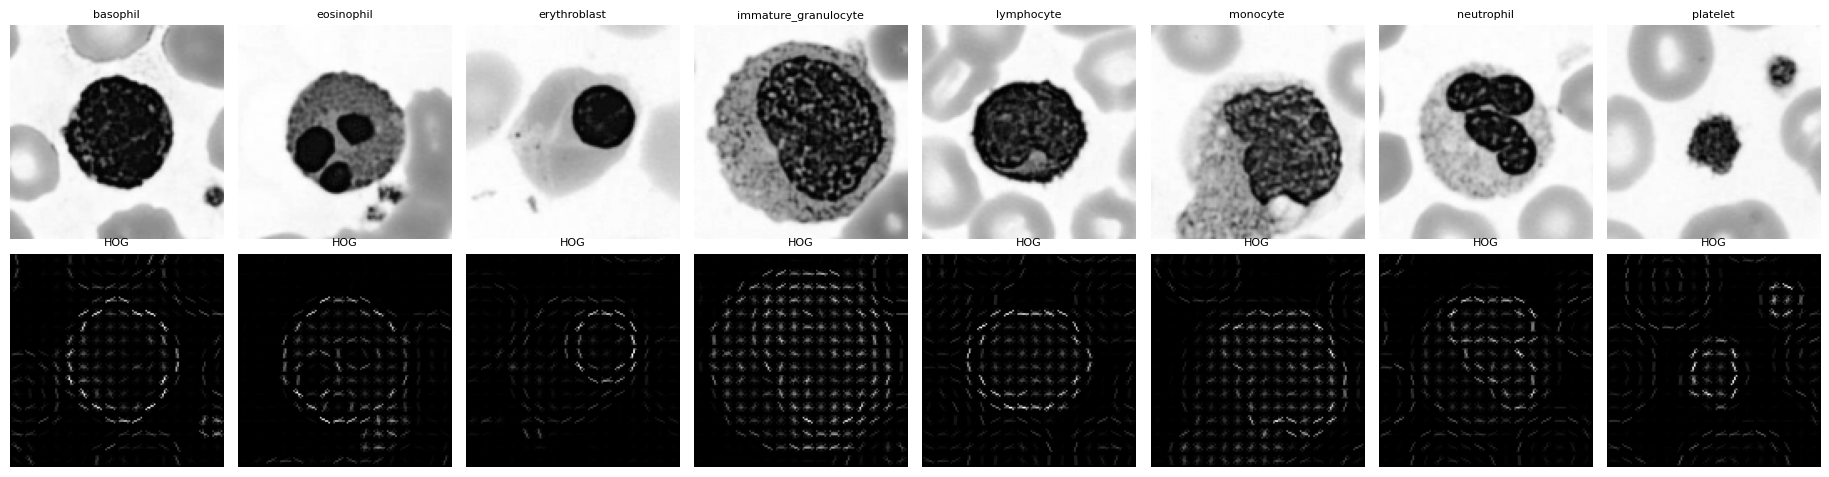

In [5]:
def hog_feat(im):
    return hog(im, **HOG_PARAMS).astype(np.float32)

def extract(imgs):
    return np.array(Parallel(n_jobs=-1, batch_size=64)(delayed(hog_feat)(im) for im in imgs))

t0 = time.time()
Xtr, Xva, Xte = extract(Xtr_img), extract(Xva_img), extract(Xte_img)
T_HOG = time.time() - t0
HOG_DIM = Xtr.shape[1]
print(f"HOG feature length: {HOG_DIM} | extraction time for all {len(Xtr)+len(Xva)+len(Xte)} images: {T_HOG:.1f}s")

fig, ax = plt.subplots(2, K, figsize=(2.3 * K, 4.8))
for j in range(K):
    im = Xtr_img[np.where(ytr == j)[0][0]]
    _, vis = hog(im, visualize=True, **HOG_PARAMS)
    ax[0, j].imshow(im, cmap="gray"); ax[0, j].set_title(classes[j], fontsize=8); ax[0, j].axis("off")
    ax[1, j].imshow(vis, cmap="gray"); ax[1, j].set_title("HOG", fontsize=8); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/hog_examples.png", dpi=120); plt.show()

In [6]:
def full_metrics(yt, yp, k=None):
    k = k or K
    cm = confusion_matrix(yt, yp, labels=np.arange(k))
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - (tp + fp + fn)
    spec = np.mean(tn / np.maximum(tn + fp, 1))          # one-vs-rest specificity, macro-averaged over classes
    return {"Accuracy (%)": 100 * accuracy_score(yt, yp),
            "Precision (Macro, %)": 100 * precision_score(yt, yp, average="macro", zero_division=0),
            "Recall (Macro, %)": 100 * recall_score(yt, yp, average="macro", zero_division=0),
            "Macro-F1 (%)": 100 * f1_score(yt, yp, average="macro", zero_division=0),
            "Weighted-F1 (%)": 100 * f1_score(yt, yp, average="weighted", zero_division=0),
            "Balanced accuracy (%)": 100 * balanced_accuracy_score(yt, yp),
            "Specificity (Macro, %)": 100 * spec,
            "Cohen's kappa": cohen_kappa_score(yt, yp),
            "Matthews correlation coefficient": matthews_corrcoef(yt, yp)}

## Baseline HOG + SVM (RBF) with validation-set hyper-parameter tuning
To make the GA affordable, kernels are built in one matrix product (exact RBF kernel, `kernel="precomputed"`) on a stratified training subset; the final models are then trained on the **full** training set.

GA / tuning subset: (2500, 8100) | validation: (1712, 8100)
Baseline tuning done in 14s | best (validation macro-F1 on subset model): {'C': 3, 'gmult': 0.5, 'cw': 'balanced'} -> 0.7176


,C,gmult,cw,val_f1
0,3,0.5,balanced,0.7176
1,10,0.5,balanced,0.7123
2,30,0.5,none,0.7123
3,30,0.5,balanced,0.7123
4,100,0.5,balanced,0.7123
5,100,0.5,none,0.7123
6,10,0.5,none,0.7123
7,3,0.5,none,0.7076


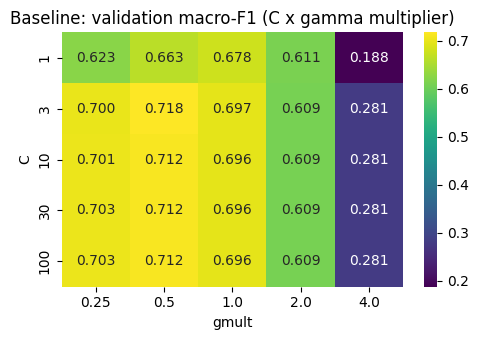

In [7]:
class FastRBF:
    # exact RBF kernel for any feature subset: ||a-b||^2 = |a|^2 + |b|^2 - 2 a.b  (one matrix product)
    def __init__(self, A, B):
        self.var = float(A.var()); self.d = A.shape[1]
        if torch is not None:
            self.A = torch.as_tensor(A, dtype=torch.float32, device=DEV)
            self.B = torch.as_tensor(B, dtype=torch.float32, device=DEV)
        else:
            self.A, self.B = A.astype(np.float32), B.astype(np.float32)
    def dist(self, idx=None):
        if torch is not None:
            if idx is None: A, B = self.A, self.B
            else:
                ii = torch.as_tensor(idx, dtype=torch.long, device=DEV); A, B = self.A[:, ii], self.B[:, ii]
            na, nb = (A * A).sum(1), (B * B).sum(1)
            Dtr = (na[:, None] + na[None, :] - 2 * (A @ A.T)).clamp_(min=0)
            Dva = (nb[:, None] + na[None, :] - 2 * (B @ A.T)).clamp_(min=0)
            return Dtr.cpu().numpy(), Dva.cpu().numpy()
        A = self.A if idx is None else self.A[:, idx]; B = self.B if idx is None else self.B[:, idx]
        na, nb = (A * A).sum(1), (B * B).sum(1)
        return (np.maximum(na[:, None] + na[None, :] - 2 * A @ A.T, 0),
                np.maximum(nb[:, None] + na[None, :] - 2 * B @ A.T, 0))
    def score(self, Dtr, Dva, n_sel, C, gmult, cw, y_tr, y_va):
        gamma = gmult / (n_sel * self.var)                  # same rule as sklearn gamma="scale", times a multiplier
        clf = SVC(kernel="precomputed", C=C, class_weight=CW(cw)).fit(np.exp(-gamma * Dtr), y_tr)
        return f1_score(y_va, clf.predict(np.exp(-gamma * Dva)), average="macro")

if N_SUB >= len(ytr): sub_idx = np.arange(len(ytr))
else: sub_idx, _ = train_test_split(np.arange(len(ytr)), train_size=N_SUB, stratify=ytr, random_state=SEED)
Xsub, ysub = Xtr[sub_idx], ytr[sub_idx]
fast = FastRBF(Xsub, Xva)
print("GA / tuning subset:", Xsub.shape, "| validation:", Xva.shape)

GRID = dict(C=[1, 3, 10, 30, 100], gmult=[0.25, 0.5, 1, 2, 4], cw=["none", "balanced"])
CW = lambda s: None if s in (None, "none") else s      # class_weight label -> sklearn value
def tune(Dtr, Dva, n_sel, grid=GRID):
    rows = []
    for C in grid["C"]:
        for g in grid["gmult"]:
            for cw in grid["cw"]:
                rows.append(dict(C=C, gmult=g, cw=cw, val_f1=fast.score(Dtr, Dva, n_sel, C, g, cw, ysub, yva)))
    return pd.DataFrame(rows).sort_values("val_f1", ascending=False).reset_index(drop=True)

t0 = time.time()
D_full_tr, D_full_va = fast.dist(None)
tune_base = tune(D_full_tr, D_full_va, HOG_DIM)
BEST = tune_base.iloc[0][["C", "gmult", "cw"]].to_dict()
print(f"Baseline tuning done in {time.time()-t0:.0f}s | best (validation macro-F1 on subset model): {BEST} -> {tune_base.val_f1.iloc[0]:.4f}")
display(tune_base.head(8).round(4))
pv = tune_base[tune_base.cw == BEST["cw"]].pivot(index="C", columns="gmult", values="val_f1")
plt.figure(figsize=(5, 3.5)); sns.heatmap(pv, annot=True, fmt=".3f", cmap="viridis"); plt.title("Baseline: validation macro-F1 (C x gamma multiplier)")
plt.tight_layout(); plt.savefig(f"{OUT}/baseline_tuning.png", dpi=120); plt.show()

## Tasks 5-6: Genetic Algorithm for HOG feature selection
* **Chromosome:** binary vector with one gene per HOG feature (1 = keep).
* **Fitness:** `validation macro-F1 − α · (selected features / all features)` (feature-selection penalty).
* **Initial population:** random masks of varied density plus three seeded individuals (all features, top-50 % and top-25 % by ANOVA F-score).
* **Selection:** tournament (k = 3) with elitism. **Crossover:** uniform. **Mutation:** per-gene bit flip. Repair keeps at least `MIN_FEATURES` genes.

In [8]:
Fscore, _ = f_classif(Xsub, ysub); Fscore = np.nan_to_num(Fscore)
rank = np.argsort(-Fscore)
def top_mask(frac):
    m = np.zeros(HOG_DIM, bool); m[rank[:int(frac * HOG_DIM)]] = True; return m

def repair(ind, rng):
    if ind.sum() < MIN_FEATURES:
        off = np.flatnonzero(~ind); ind[rng.choice(off, MIN_FEATURES - int(ind.sum()), replace=False)] = True
    return ind

def run_ga(name, cfg, seed=SEED):
    rng = np.random.default_rng(seed); d = HOG_DIM; cache = {}
    def fitness(ind):
        key = np.packbits(ind).tobytes()
        if key not in cache:
            idx = np.flatnonzero(ind); Dtr, Dva = fast.dist(idx)
            f1 = fast.score(Dtr, Dva, len(idx), BEST["C"], BEST["gmult"], BEST["cw"], ysub, yva)
            cache[key] = (f1 - cfg["alpha"] * len(idx) / d, f1)
        return cache[key]
    # population initialisation
    P = np.array([rng.random(d) < rng.uniform(0.3, 0.8) for _ in range(cfg["pop"])])
    for i, s in enumerate([np.ones(d, bool), top_mask(0.5), top_mask(0.25)][:cfg["pop"]]): P[i] = s
    hist, best_ind, best_fit, t0 = [], None, -9, time.time()
    for g in range(cfg["gens"]):
        res = np.array([fitness(ind) for ind in P]); fits = res[:, 0]
        b = int(np.argmax(fits))
        if fits[b] > best_fit: best_fit, best_ind = fits[b], P[b].copy()
        hist.append(dict(gen=g + 1, best_fitness=fits[b], mean_fitness=fits.mean(), best_val_f1=res[b, 1],
                         best_n_features=int(P[b].sum()), mean_n_features=float(P.sum(1).mean())))
        print(f"  [{name}] gen {g+1:2d}/{cfg['gens']}  best fitness {fits[b]:.4f}  val F1 {res[b,1]:.4f}  "
              f"features {int(P[b].sum()):5d}  ({time.time()-t0:.0f}s)")
        # next generation: elitism + tournament selection + uniform crossover + bit-flip mutation
        new = [P[i].copy() for i in np.argsort(-fits)[:cfg["elite"]]]
        pick = lambda: (lambda ix: ix[np.argmax(fits[ix])])(rng.integers(0, cfg["pop"], cfg["tour"]))
        while len(new) < cfg["pop"]:
            p1, p2 = P[pick()], P[pick()]
            if rng.random() < cfg["pc"]:
                m = rng.random(d) < 0.5; c1, c2 = np.where(m, p1, p2), np.where(m, p2, p1)
            else: c1, c2 = p1.copy(), p2.copy()
            for c in (c1, c2):
                c = repair(c ^ (rng.random(d) < cfg["pm"]), rng); new.append(c)
        P = np.array(new[:cfg["pop"]])
    return dict(name=name, cfg=cfg, mask=best_ind, fitness=best_fit, hist=pd.DataFrame(hist),
                time=time.time() - t0, evals=len(cache))

In [9]:
GA = {}
for name, cfg in GA_CONFIGS.items():
    print(f"=== {name}: {cfg} ===")
    GA[name] = run_ga(name, cfg)
    print(f"  finished in {GA[name]['time']:.0f}s | {GA[name]['evals']} unique fitness evaluations | selected {int(GA[name]['mask'].sum())} features")

=== GA-1: {'pop': 16, 'gens': 20, 'pc': 0.9, 'pm': 0.002, 'alpha': 0.02, 'tour': 3, 'elite': 2} ===
  [GA-1] gen  1/20  best fitness 0.7108  val F1 0.7194  features  3444  (6s)
  [GA-1] gen  2/20  best fitness 0.7195  val F1 0.7287  features  3725  (10s)
  [GA-1] gen  3/20  best fitness 0.7224  val F1 0.7314  features  3611  (14s)
  [GA-1] gen  4/20  best fitness 0.7242  val F1 0.7333  features  3673  (18s)
  [GA-1] gen  5/20  best fitness 0.7258  val F1 0.7348  features  3649  (22s)
  [GA-1] gen  6/20  best fitness 0.7258  val F1 0.7348  features  3649  (26s)
  [GA-1] gen  7/20  best fitness 0.7258  val F1 0.7348  features  3649  (30s)
  [GA-1] gen  8/20  best fitness 0.7272  val F1 0.7363  features  3668  (34s)
  [GA-1] gen  9/20  best fitness 0.7290  val F1 0.7381  features  3678  (38s)
  [GA-1] gen 10/20  best fitness 0.7290  val F1 0.7381  features  3671  (43s)
  [GA-1] gen 11/20  best fitness 0.7321  val F1 0.7411  features  3667  (47s)
  [GA-1] gen 12/20  best fitness 0.7321  va

## Task 9: GA fitness across generations and feature counts

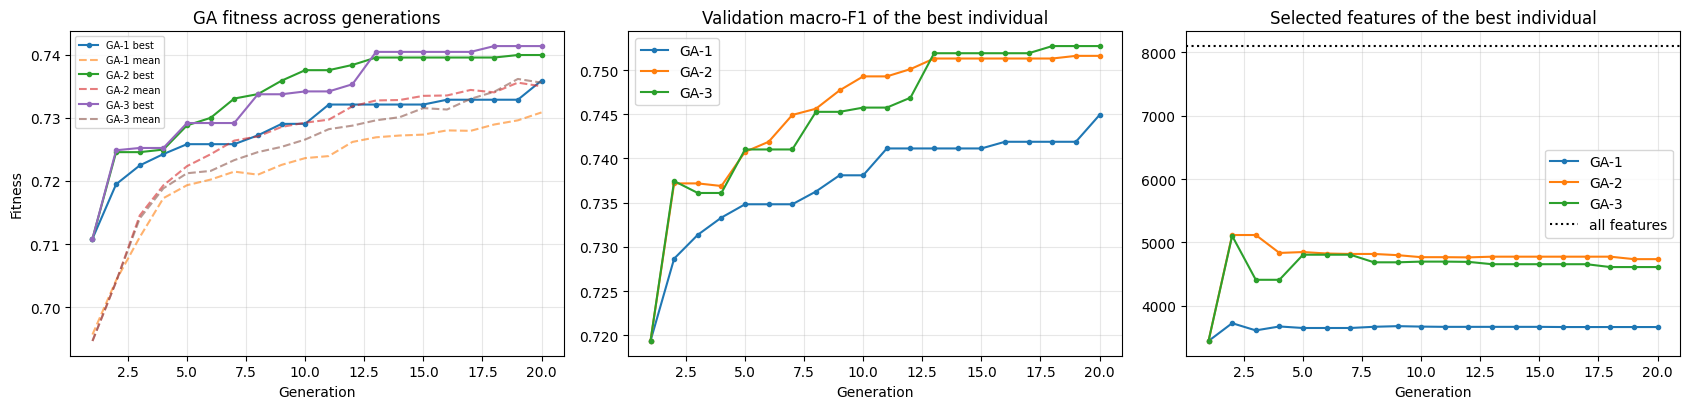

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for name, r in GA.items():
    h = r["hist"]
    ax[0].plot(h.gen, h.best_fitness, marker="o", ms=3, label=f"{name} best")
    ax[0].plot(h.gen, h.mean_fitness, ls="--", alpha=.6, label=f"{name} mean")
    ax[1].plot(h.gen, h.best_val_f1, marker="o", ms=3, label=name)
    ax[2].plot(h.gen, h.best_n_features, marker="o", ms=3, label=name)
ax[0].set_title("GA fitness across generations"); ax[0].set_xlabel("Generation"); ax[0].set_ylabel("Fitness"); ax[0].legend(fontsize=7)
ax[1].set_title("Validation macro-F1 of the best individual"); ax[1].set_xlabel("Generation"); ax[1].legend()
ax[2].axhline(HOG_DIM, color="k", ls=":", label="all features"); ax[2].set_title("Selected features of the best individual")
ax[2].set_xlabel("Generation"); ax[2].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/ga_fitness_curves.png", dpi=130); plt.show()

## Task 6-7: Model selection (validation set only) and final SVM training
For each GA setting the SVM hyper-parameters are re-tuned on the selected features (validation set), the best setting is chosen by `validation macro-F1 − α·fraction`, and only then are the final models trained on the full training set. **The test set has not been used so far.**

In [11]:
sel_rows = []
for name, r in GA.items():
    idx = np.flatnonzero(r["mask"]); Dtr, Dva = fast.dist(idx)
    tn = tune(Dtr, Dva, len(idx), grid=dict(C=[3, 10, 30, 100], gmult=[0.5, 1, 2, 4], cw=["none", "balanced"]))
    hp = tn.iloc[0][["C", "gmult", "cw"]].to_dict()
    r["hp"] = hp; r["val_f1_tuned"] = float(tn.val_f1.iloc[0])
    r["sel_score"] = r["val_f1_tuned"] - r["cfg"]["alpha"] * len(idx) / HOG_DIM
    sel_rows.append({"GA setting": name, "Population": r["cfg"]["pop"], "Mutation prob.": r["cfg"]["pm"], "Crossover prob.": r["cfg"]["pc"],
                     "Penalty alpha": r["cfg"]["alpha"], "Generations": r["cfg"]["gens"], "Fitness evals": r["evals"],
                     "Features kept": len(idx), "Reduction (%)": round(100 * (1 - len(idx) / HOG_DIM), 1),
                     "GA best val F1": round(r["hist"].best_val_f1.max(), 4), "Tuned val F1": round(r["val_f1_tuned"], 4),
                     "Selection score": round(r["sel_score"], 4), "GA time (s)": round(r["time"], 1)})
ga_table = pd.DataFrame(sel_rows); display(ga_table)
ga_table.to_csv(f"{OUT}/table_ga_settings.csv", index=False)
BEST_GA = max(GA, key=lambda n: GA[n]["sel_score"])
print("Selected GA setting (by validation only):", BEST_GA)

,GA setting,Population,Mutation prob.,Crossover prob.,Penalty alpha,Generations,Fitness evals,Features kept,Reduction (%),GA best val F1,Tuned val F1,Selection score,GA time (s)
0,GA-1,16,0.002,0.9,0.02,20,282,3664,54.8,0.7449,0.7449,0.7359,83.8
1,GA-2,24,0.005,0.9,0.02,20,442,4736,41.5,0.7516,0.7516,0.7399,134.9
2,GA-3,24,0.010,0.9,0.02,20,442,4611,43.1,0.7527,0.7527,0.7413,139.0


Selected GA setting (by validation only): GA-3


In [12]:
def fit_svm(X, y, idx, hp):
    n = X.shape[1] if idx is None else len(idx); Xs = X if idx is None else X[:, idx]
    clf = SVC(kernel="rbf", C=hp["C"], gamma=hp["gmult"] / (n * fast.var), class_weight=CW(hp["cw"]), cache_size=2000)
    t0 = time.time(); clf.fit(Xs, y); return clf, time.time() - t0

sel = GA[BEST_GA]; sel_idx = np.flatnonzero(sel["mask"])
base_clf, T_fit_base = fit_svm(Xtr, ytr, None, BEST)
ga_clf,   T_fit_ga   = fit_svm(Xtr, ytr, sel_idx, sel["hp"])
print(f"Training time on full train set ({len(ytr)} images): baseline {T_fit_base:.1f}s | GA-HOG {T_fit_ga:.1f}s")

val_base, val_ga = full_metrics(yva, base_clf.predict(Xva)), full_metrics(yva, ga_clf.predict(Xva[:, sel_idx]))
val_tab = pd.DataFrame({"HOG + SVM": val_base, "GA-HOG + SVM": val_ga}); val_tab["Difference"] = val_tab.iloc[:, 1] - val_tab.iloc[:, 0]
print("VALIDATION results (used for model selection):"); display(val_tab.round(3))

Training time on full train set (11959 images): baseline 578.4s | GA-HOG 290.3s
VALIDATION results (used for model selection):


,HOG + SVM,GA-HOG + SVM,Difference
Accuracy (%),80.783,80.607,-0.175
"Precision (Macro, %)",80.177,80.087,-0.090
"Recall (Macro, %)",80.408,80.290,-0.119
Macro-F1 (%),80.211,80.081,-0.130
Weighted-F1 (%),80.778,80.655,-0.123
Balanced accuracy (%),80.408,80.290,-0.119
"Specificity (Macro, %)",97.198,97.176,-0.023
Cohen's kappa,0.776,0.774,-0.002
Matthews correlation coefficient,0.776,0.774,-0.002


## Task 8: Final evaluation on the test set (run once, after model selection)

In [13]:
t0 = time.time(); pred_base = base_clf.predict(Xte);              T_inf_base = time.time() - t0
t0 = time.time(); pred_ga   = ga_clf.predict(Xte[:, sel_idx]);    T_inf_ga   = time.time() - t0
mb, mg = full_metrics(yte, pred_base), full_metrics(yte, pred_ga)

table2 = pd.DataFrame({"HOG + SVM (Baseline)": mb, "GA-HOG + SVM (Proposed)": mg})
table2["Improvement"] = table2.iloc[:, 1] - table2.iloc[:, 0]
table2.index.name = "Metric"
print("Table 2. Main performance comparison (TEST set). Improvement = Proposed - Baseline (percentage points; raw difference for kappa / MCC).")
print("Specificity: one-vs-rest per class, macro-averaged over all classes.")
display(table2.round(3)); table2.round(4).to_csv(f"{OUT}/table2_main_comparison.csv")

# Table 1: configuration actually used
table1 = pd.DataFrame([
    ("Medical dataset", DATASET, DATASET), ("Image resolution", f"{IMG_SIZE} x {IMG_SIZE}", f"{IMG_SIZE} x {IMG_SIZE}"),
    ("HOG orientations", HOG_PARAMS["orientations"], HOG_PARAMS["orientations"]),
    ("Pixels per cell", "8 x 8", "8 x 8"), ("Cells per block", "2 x 2", "2 x 2"), ("Block normalization", "L2-Hys", "L2-Hys"),
    ("HOG features per image", HOG_DIM, len(sel_idx)),
    ("Feature selection", "None", f"Genetic Algorithm ({BEST_GA}: pop {sel['cfg']['pop']}, p_mut {sel['cfg']['pm']}, {sel['cfg']['gens']} gens, alpha {sel['cfg']['alpha']})"),
    ("Classifier", "SVM", "SVM"), ("SVM kernel", "RBF", "RBF"),
    ("SVM hyper-parameters (validation)", f"C={BEST['C']}, gamma x{BEST['gmult']}, class_weight={BEST['cw']}",
                                          f"C={sel['hp']['C']}, gamma x{sel['hp']['gmult']}, class_weight={sel['hp']['cw']}"),
    ("Hyperparameter tuning", "Validation set", "Validation set"),
    ("Data split", f"Fixed: {len(ytr)} / {len(yva)} / {len(yte)} (train / val / test)", "Identical fixed split"),
    ("Random seed", SEED, SEED)], columns=["Parameter", "Baseline: HOG + SVM", "Proposed: GA-HOG + SVM"])
print("\nTable 1. Experimental configuration"); display(table1); table1.to_csv(f"{OUT}/table1_configuration.csv", index=False)

# Table 3: dimensionality and computational cost
table3 = pd.DataFrame({
    "HOG + SVM": {"Features": HOG_DIM, "HOG extraction, all images (s)": T_HOG, "GA search (s)": 0.0,
                  "SVM training, full train set (s)": T_fit_base, "Test inference (s)": T_inf_base,
                  "Inference per image (ms)": 1000 * T_inf_base / len(yte), "Support vectors": int(base_clf.n_support_.sum())},
    "GA-HOG + SVM": {"Features": len(sel_idx), "HOG extraction, all images (s)": T_HOG, "GA search (s)": sel["time"],
                     "SVM training, full train set (s)": T_fit_ga, "Test inference (s)": T_inf_ga,
                     "Inference per image (ms)": 1000 * T_inf_ga / len(yte), "Support vectors": int(ga_clf.n_support_.sum())}})
table3["Change"] = table3.iloc[:, 1] - table3.iloc[:, 0]
print("\nTable 3. Dimensionality and computational time"); display(table3.round(3)); table3.round(4).to_csv(f"{OUT}/table3_cost.csv")
print(f"Total GA search time for all {len(GA)} settings: {sum(r['time'] for r in GA.values()):.0f}s")

Table 2. Main performance comparison (TEST set). Improvement = Proposed - Baseline (percentage points; raw difference for kappa / MCC).
Specificity: one-vs-rest per class, macro-averaged over all classes.


,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
Metric,,,
Accuracy (%),79.509,79.772,0.263
"Precision (Macro, %)",79.013,79.090,0.077
"Recall (Macro, %)",78.583,79.207,0.624
Macro-F1 (%),78.750,79.106,0.356
Weighted-F1 (%),79.534,79.818,0.284
Balanced accuracy (%),78.583,79.207,0.624
"Specificity (Macro, %)",97.009,97.056,0.047
Cohen's kappa,0.761,0.764,0.003
Matthews correlation coefficient,0.761,0.764,0.003



Table 1. Experimental configuration


,Parameter,Baseline: HOG + SVM,Proposed: GA-HOG + SVM
0,Medical dataset,bloodmnist,bloodmnist
1,Image resolution,128 x 128,128 x 128
2,HOG orientations,9,9
3,Pixels per cell,8 x 8,8 x 8
4,Cells per block,2 x 2,2 x 2
5,Block normalization,L2-Hys,L2-Hys
6,HOG features per image,8100,4611
7,Feature selection,None,"Genetic Algorithm (GA-3: pop 24, p_mut 0.01, 2..."
8,Classifier,SVM,SVM
9,SVM kernel,RBF,RBF



Table 3. Dimensionality and computational time


,HOG + SVM,GA-HOG + SVM,Change
Features,8100.000,4611.000,-3489.000
"HOG extraction, all images (s)",101.272,101.272,0.000
GA search (s),0.000,139.037,139.037
"SVM training, full train set (s)",578.423,290.296,-288.127
Test inference (s),291.672,167.197,-124.475
Inference per image (ms),85.259,48.874,-36.386
Support vectors,9884.000,9616.000,-268.000


Total GA search time for all 3 settings: 358s


Table 4. Per-class results (TEST set)


,Class,Support,F1 baseline (%),F1 GA-HOG (%),Recall baseline (%),Recall GA-HOG (%),F1 change
0,basophil,244,71.90,71.84,71.31,72.13,-0.06
1,eosinophil,624,77.55,78.03,80.29,79.97,0.48
2,erythroblast,311,84.23,84.65,80.71,84.24,0.42
3,immature_granulocyte,579,65.56,64.90,64.77,63.56,-0.66
4,lymphocyte,243,84.65,85.53,83.95,83.95,0.89
5,monocyte,284,61.51,62.52,63.03,65.49,1.01
6,neutrophil,666,87.73,88.10,85.89,85.59,0.37
7,platelet,470,96.87,97.27,98.72,98.72,0.41


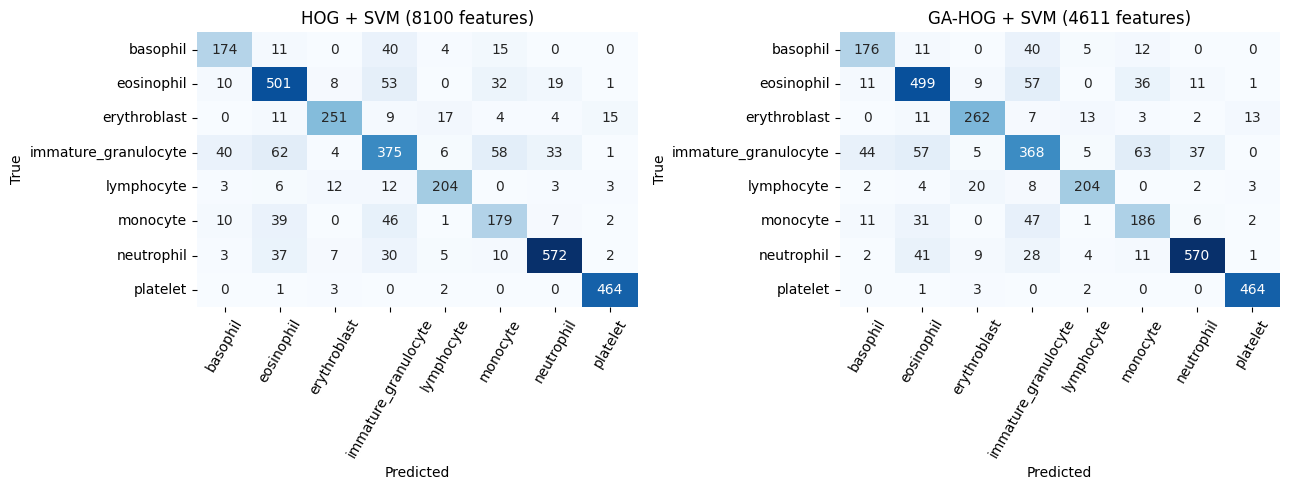

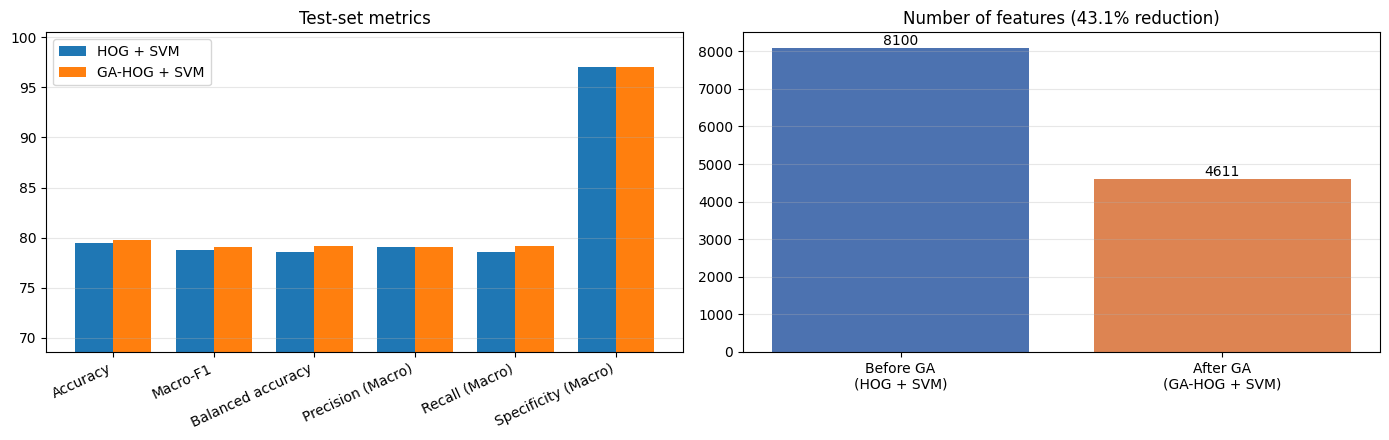

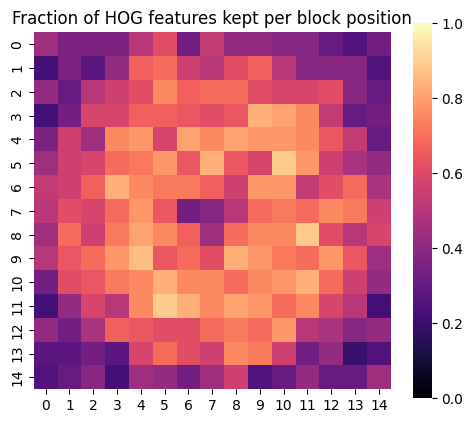

In [14]:
# per-class comparison, confusion matrices, metric bars, feature reduction
rb = classification_report(yte, pred_base, target_names=classes, output_dict=True, zero_division=0)
rg = classification_report(yte, pred_ga, target_names=classes, output_dict=True, zero_division=0)
per_class = pd.DataFrame({"Class": classes, "Support": [int(rb[c]["support"]) for c in classes],
                          "F1 baseline (%)": [100 * rb[c]["f1-score"] for c in classes],
                          "F1 GA-HOG (%)": [100 * rg[c]["f1-score"] for c in classes],
                          "Recall baseline (%)": [100 * rb[c]["recall"] for c in classes],
                          "Recall GA-HOG (%)": [100 * rg[c]["recall"] for c in classes]})
per_class["F1 change"] = per_class["F1 GA-HOG (%)"] - per_class["F1 baseline (%)"]
print("Table 4. Per-class results (TEST set)"); display(per_class.round(2)); per_class.round(3).to_csv(f"{OUT}/table4_per_class.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, p, t in [(ax[0], pred_base, f"HOG + SVM ({HOG_DIM} features)"), (ax[1], pred_ga, f"GA-HOG + SVM ({len(sel_idx)} features)")]:
    cm = confusion_matrix(yte, p, labels=np.arange(K))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=classes, yticklabels=classes)
    a.set_title(t); a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices.png", dpi=130); plt.show()

keys = ["Accuracy (%)", "Macro-F1 (%)", "Balanced accuracy (%)", "Precision (Macro, %)", "Recall (Macro, %)", "Specificity (Macro, %)"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(keys)); w = 0.38
ax[0].bar(x - w/2, [mb[k] for k in keys], w, label="HOG + SVM"); ax[0].bar(x + w/2, [mg[k] for k in keys], w, label="GA-HOG + SVM")
ax[0].set_xticks(x); ax[0].set_xticklabels([k.replace(" (%)", "").replace(", %)", ")") for k in keys], rotation=25, ha="right")
lo = min(min(mb[k] for k in keys), min(mg[k] for k in keys)); ax[0].set_ylim(max(0, lo - 10), 100.5)
ax[0].set_title("Test-set metrics"); ax[0].legend(); ax[0].grid(axis="y", alpha=.3)
bars = ax[1].bar(["Before GA\n(HOG + SVM)", "After GA\n(GA-HOG + SVM)"], [HOG_DIM, len(sel_idx)], color=["#4c72b0", "#dd8452"])
for b, v in zip(bars, [HOG_DIM, len(sel_idx)]): ax[1].text(b.get_x() + b.get_width()/2, v, f"{v}", ha="center", va="bottom")
ax[1].set_title(f"Number of features ({100*(1-len(sel_idx)/HOG_DIM):.1f}% reduction)"); ax[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/metric_and_feature_comparison.png", dpi=130); plt.show()

# where does the GA keep features? (fraction of kept features per HOG block position)
nb = IMG_SIZE // 8 - 1
if HOG_DIM == nb * nb * 36:
    plt.figure(figsize=(5, 4.3)); sns.heatmap(sel["mask"].reshape(nb, nb, 36).mean(2), cmap="magma", vmin=0, vmax=1, square=True)
    plt.title("Fraction of HOG features kept per block position"); plt.tight_layout(); plt.savefig(f"{OUT}/selected_feature_map.png", dpi=130); plt.show()

### Is the difference statistically meaningful?

In [15]:
from scipy.stats import binomtest, chi2
ok_b, ok_g = pred_base == yte, pred_ga == yte
b, c = int(np.sum(ok_b & ~ok_g)), int(np.sum(~ok_b & ok_g))        # baseline-only correct, GA-only correct
if b + c == 0: p_mc = 1.0
elif b + c < 25: p_mc = binomtest(min(b, c), b + c, 0.5).pvalue
else: p_mc = float(chi2.sf((abs(b - c) - 1) ** 2 / (b + c), 1))
print(f"McNemar test: baseline-only correct = {b}, GA-HOG-only correct = {c}, p = {p_mc:.4f}")

rng = np.random.default_rng(SEED); diffs = []
for _ in range(1000):
    i = rng.integers(0, len(yte), len(yte))
    diffs.append(100 * (f1_score(yte[i], pred_ga[i], average="macro") - f1_score(yte[i], pred_base[i], average="macro")))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Paired bootstrap, macro-F1 difference (GA-HOG minus baseline): mean {np.mean(diffs):+.2f} pp, 95% CI [{lo:+.2f}, {hi:+.2f}] pp")

McNemar test: baseline-only correct = 90, GA-HOG-only correct = 99, p = 0.5606
Paired bootstrap, macro-F1 difference (GA-HOG minus baseline): mean +0.38 pp, 95% CI [-0.44, +1.22] pp


### Automatic summary of the actual results

In [16]:
d = table2["Improvement"]
print(f"Dataset: {DATASET} | test images: {len(yte)} | selected GA setting: {BEST_GA}")
print(f"Features: {HOG_DIM} -> {len(sel_idx)} ({100*(1-len(sel_idx)/HOG_DIM):.1f}% fewer)")
print(f"Macro-F1: {mb['Macro-F1 (%)']:.2f}% -> {mg['Macro-F1 (%)']:.2f}% ({d['Macro-F1 (%)']:+.2f} pp) | "
      f"Accuracy: {mb['Accuracy (%)']:.2f}% -> {mg['Accuracy (%)']:.2f}% ({d['Accuracy (%)']:+.2f} pp) | "
      f"Balanced acc.: {d['Balanced accuracy (%)']:+.2f} pp")
if d["Macro-F1 (%)"] > 0 and p_mc < 0.05:
    verdict = "GA-based feature selection IMPROVED classification performance (statistically significant) while reducing dimensionality."
elif d["Macro-F1 (%)"] > 0:
    verdict = "GA-based feature selection gave a small gain in macro-F1 that is NOT statistically significant, while reducing dimensionality."
elif d["Macro-F1 (%)"] > -0.5:
    verdict = "GA-based feature selection kept performance essentially unchanged while reducing dimensionality (a compression benefit, not an accuracy gain)."
else:
    verdict = "GA-based feature selection did NOT improve performance on this split; the baseline was better."
print("Verdict:", verdict)
print(f"Training time {T_fit_base:.1f}s -> {T_fit_ga:.1f}s | inference {1000*T_inf_base/len(yte):.2f} -> {1000*T_inf_ga/len(yte):.2f} ms/image | "
      f"extra one-off GA cost: {sel['time']:.0f}s")

Dataset: bloodmnist | test images: 3421 | selected GA setting: GA-3
Features: 8100 -> 4611 (43.1% fewer)
Macro-F1: 78.75% -> 79.11% (+0.36 pp) | Accuracy: 79.51% -> 79.77% (+0.26 pp) | Balanced acc.: +0.62 pp
Verdict: GA-based feature selection gave a small gain in macro-F1 that is NOT statistically significant, while reducing dimensionality.
Training time 578.4s -> 290.3s | inference 85.26 -> 48.87 ms/image | extra one-off GA cost: 139s
